# Estimer le niveau par produit scalaire avec des photos de référence

**Idée** : on dispose de quelques photos de **référence** dont on connaît le niveau d'eau (relevé à la main). Pour une nouvelle photo, on calcule son produit scalaire avec chaque référence et on prend le niveau de la référence la plus « ressemblante » (plus grande valeur).

**Niveau** = ordonnée moyenne $y$ (en pixels) de la frontière eau / berge d'en face, relevée à la main sur 10 colonnes ($x$ = 100, 300, …, 1900). Plus $y$ est **petit**, plus la frontière est **haute** dans l'image, donc plus l'eau est **haute**.

Chaque photo est transformée en un vecteur : la bande utile $y$ ∈ [500, 1200] en couleur, réduite à 1/8 (87 × 240 pixels × 3 canaux = 62 640 valeurs entre 0 et 1).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from bucket import Bucket, DATA_DIR

plt.rcParams["figure.dpi"] = 70
b = Bucket()
CROP_Y0, CROP_Y1, W0 = 500, 1200, 1919   # bande utile (y), largeur des images
EXT = [0, W0, CROP_Y1, CROP_Y0]


def fetch(key):
    """Chemin local de l'image, téléchargée dans data/raw/ si besoin."""
    p = DATA_DIR / key
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        b.s3.download_file(b.name, key, str(p))
    return p


def load_band(key, scale=1):
    """Bande CROP_Y0-CROP_Y1 en couleur (float 0-1), décodée à 1/scale."""
    im = Image.open(fetch(key))
    if scale > 1:
        im.draft("RGB", (im.size[0] // scale, im.size[1] // scale))
    s = W0 / im.size[0]
    im = im.convert("RGB").crop((0, round(CROP_Y0 / s), im.size[0], round(CROP_Y1 / s)))
    return np.asarray(im, dtype=np.float64) / 255

## 1. Les données
- **10 références** : photos nettes et lumineuses (10h-15h), sur 10 jours différents, choisies pour couvrir des niveaux bien différents ;
- **6 photos test** tirées au hasard parmi les photos de jour de bonne qualité (hors jours des références).

Les niveaux ont été relevés à la main. Celui du test du 08/09 est incertain (image sombre et bleutée).

In [2]:
# (date, clé dans le bucket, niveau relevé à la main en px)
REFS = [
    ("2026-06-04 11:15", "romanche-01/2026/06/04/111505_a21b9b63_s.jpg", 703.9),
    ("2026-06-02 14:45", "romanche-01/2026/06/02/144502_3ec94d08_s.jpg", 726.2),
    ("2026-06-18 14:45", "romanche-01/2026/06/18/144511_8f807811_s.jpg", 743.4),
    ("2026-05-30 13:15", "romanche-01/2026/05/30/131502_e1fcacb9_s.jpg", 768.7),
    ("2026-06-27 14:30", "romanche-01/2026/06/27/143011_c4b1a8e9_s.jpg", 781.8),
    ("2026-06-21 14:15", "romanche-01/2026/06/21/141510_f458a9a7_s.jpg", 798.1),
    ("2026-10-11 10:15", "romanche-01/2026/10/11/101511_c00adf10_s.jpg", 818.7),
    ("2026-10-09 13:30", "romanche-01/2026/10/09/133005_cf74ab5d_s.jpg", 833.6),
    ("2026-07-05 14:30", "romanche-01/2026/07/05/143006_df88145e_s.jpg", 848.6),
    ("2026-10-08 11:30", "romanche-01/2026/10/08/113007_d44efe78_s.jpg", 858.8),
]
TESTS = [
    ("2026-06-28 15:00", "romanche-01/2026/06/28/150011_c9e5bac5_s.jpg", 779.5),
    ("2026-09-08 09:30", "romanche-01/2026/09/08/093006_d6c8de3d_s.jpg", 776.5),
    ("2026-09-16 14:30", "romanche-01/2026/09/16/143011_050b8840_s.jpg", 861.9),
    ("2026-09-27 06:45", "romanche-01/2026/09/27/064506_8c73e49d_s.jpg", 861.3),
    ("2026-10-01 07:15", "romanche-01/2026/10/01/071511_470df292_s.jpg", 865.6),
    ("2026-10-28 10:30", "romanche-01/2026/10/28/103006_3051b4fc_s.jpg", 856.1),
]
REFS.sort(key=lambda r: r[2])   # références triées par niveau
lv_ref = np.array([r[2] for r in REFS])
lv_test = np.array([t[2] for t in TESTS])
print(len(REFS), 'références, niveaux de', lv_ref.min(), 'à', lv_ref.max(), 'px')

10 références, niveaux de 703.9 à 858.8 px


### Les références (ligne jaune = niveau relevé)

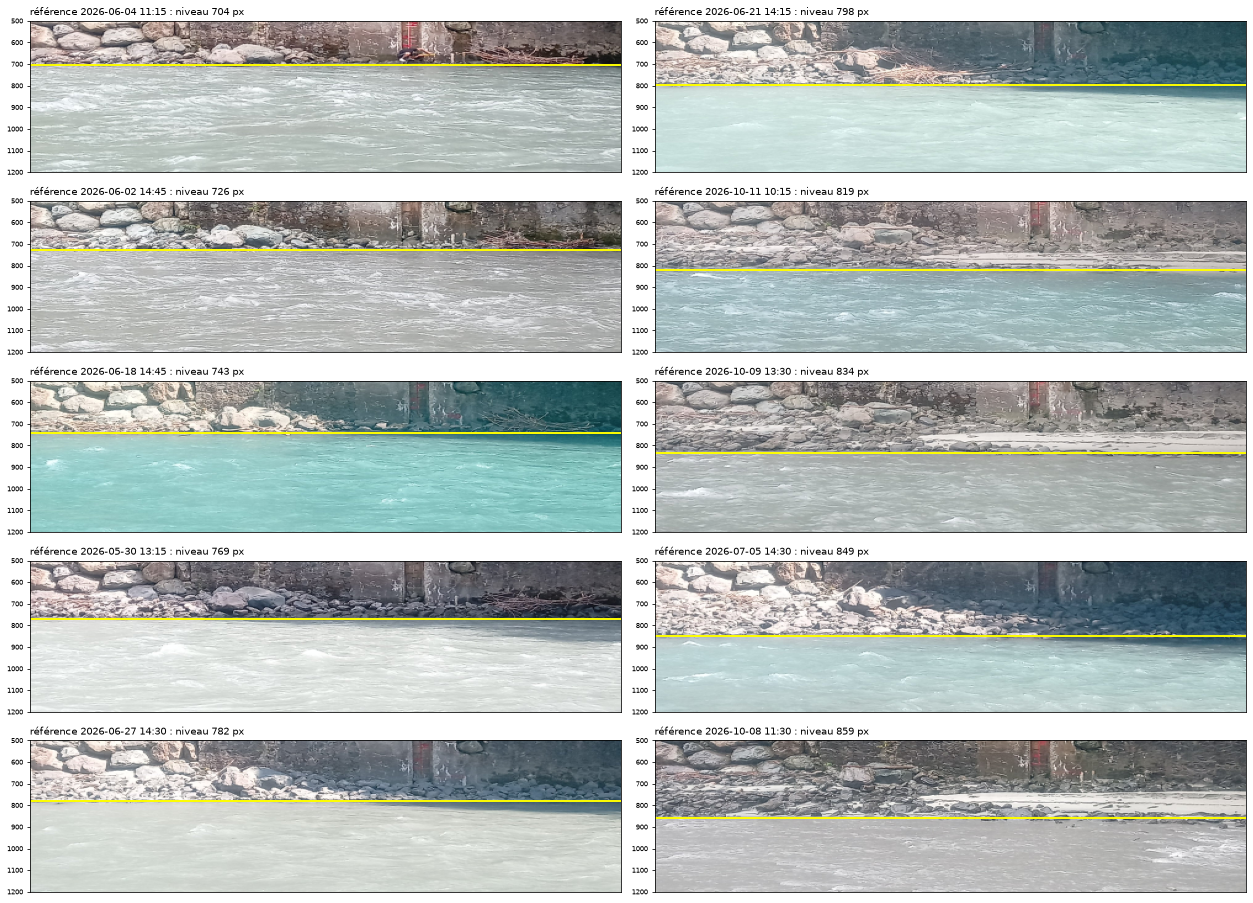

In [3]:
def show_band(ax, key, level, title):
    ax.imshow(load_band(key, 4), extent=EXT, aspect="auto")
    ax.axhline(level, color="yellow", lw=2)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks([]); ax.tick_params(labelsize=7)


fig, ax = plt.subplots(5, 2, figsize=(18, 13))
for a, (d, k, lv) in zip(ax.T.ravel(), REFS):
    show_band(a, k, lv, f"référence {d} : niveau {lv:.0f} px")
plt.tight_layout(); plt.show()

### Les photos test

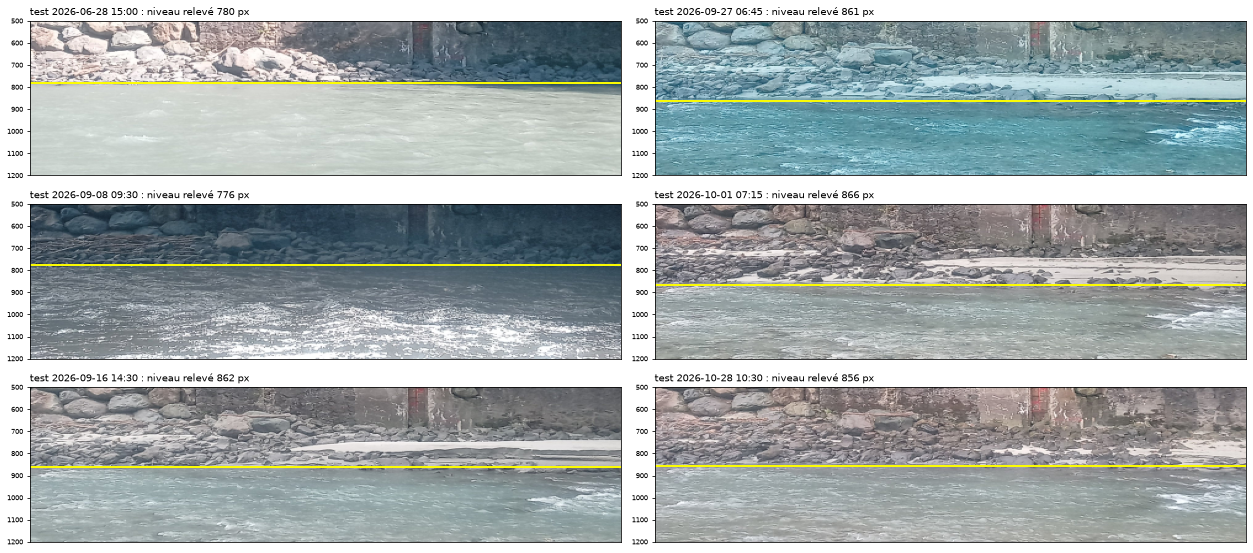

In [4]:
fig, ax = plt.subplots(3, 2, figsize=(18, 8))
for a, (d, k, lv) in zip(ax.T.ravel(), TESTS):
    show_band(a, k, lv, f"test {d} : niveau relevé {lv:.0f} px")
plt.tight_layout(); plt.show()

## 2. Trois façons de calculer le produit scalaire
Pour une photo test $x$ et une référence $r$ (vecteurs de 62 640 valeurs) :

| mesure | formule | ce qu'elle ignore |
|---|---|---|
| produit scalaire brut | $\langle x, r \rangle$ | rien |
| cosinus | $\dfrac{\langle x, r\rangle}{\|x\|\,\|r\|}$ | un facteur de luminosité global |
| corrélation | $\dfrac{1}{p}\langle \tilde{x}, \tilde{r} \rangle$ avec $\tilde{x} = \dfrac{x - \bar{x}}{\sigma_x}$ | la luminosité **et** le contraste |

($\bar{x}$ et $\sigma_x$ : moyenne et écart-type des valeurs de l'image elle-même, $p$ = 62 640).

In [5]:
R = np.stack([load_band(k, 8).ravel() for _, k, _ in REFS])
T = np.stack([load_band(k, 8).ravel() for _, k, _ in TESTS])


def zscore(M):
    return (M - M.mean(axis=1, keepdims=True)) / M.std(axis=1, keepdims=True)


MESURES = {
    "produit scalaire brut": T @ R.T,
    "cosinus": (T / np.linalg.norm(T, axis=1, keepdims=True)) @ (R / np.linalg.norm(R, axis=1, keepdims=True)).T,
    "corrélation": zscore(T) @ zscore(R).T / T.shape[1],
}
print("matrices (tests x références) :", {n: M.shape for n, M in MESURES.items()})

matrices (tests x références) : {'produit scalaire brut': (6, 10), 'cosinus': (6, 10), 'corrélation': (6, 10)}


## 3. Toutes les valeurs
Une ligne par photo test, une colonne par référence (triées par niveau). La case encadrée en rouge est le **maximum** de la ligne : c'est la référence choisie. La couleur est normalisée ligne par ligne pour bien voir où se trouve le maximum.

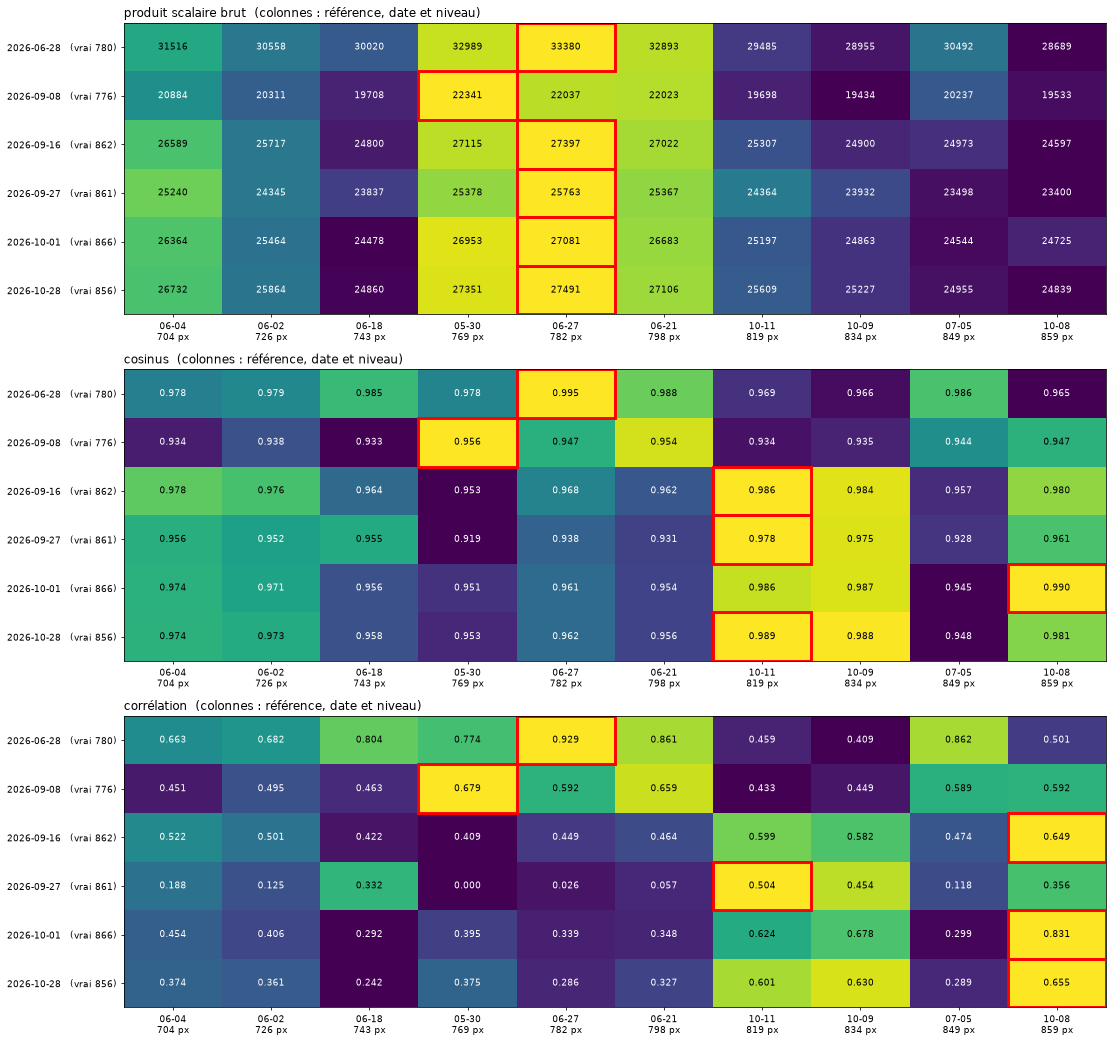

In [6]:
col_lab = [f"{d[5:10]}\n{lv:.0f} px" for d, _, lv in REFS]
row_lab = [f"{d[:11]}  (vrai {lv:.0f})" for d, _, lv in TESTS]
fig, ax = plt.subplots(3, 1, figsize=(16, 15))
for a, (name, M) in zip(ax, MESURES.items()):
    Mn = (M - M.min(axis=1, keepdims=True)) / np.ptp(M, axis=1, keepdims=True)   # normalisé par ligne
    a.imshow(Mn, cmap="viridis", aspect="auto")
    fmt = "{:.0f}" if name == "produit scalaire brut" else "{:.3f}"
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            a.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=9,
                   color="black" if Mn[i, j] > 0.6 else "white")
        j = int(np.argmax(M[i]))
        a.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="red", lw=3))
    a.set_xticks(range(len(REFS)), col_lab, fontsize=9); a.set_yticks(range(len(TESTS)), row_lab, fontsize=9)
    a.set_title(name + "  (colonnes : référence, date et niveau)", loc="left")
plt.tight_layout(); plt.show()

## 4. Résumé : niveau prédit par chaque mesure

In [7]:
print(f"{'test':18s} {'vrai':>6s} | " + " | ".join(f"{n:>24s}" for n in MESURES))
erreurs = {n: [] for n in MESURES}
for i, (d, _, lv) in enumerate(TESTS):
    cells = []
    for n, M in MESURES.items():
        p = lv_ref[int(np.argmax(M[i]))]
        erreurs[n].append(p - lv)
        cells.append(f"{p:6.0f}  ({p - lv:+5.0f} px)".rjust(24))
    print(f"{d:18s} {lv:6.0f} | " + " | ".join(cells))
print()
for n, e in erreurs.items():
    e = np.abs(e)
    print(f"{n:24s} erreur médiane {np.median(e):5.1f} px | erreur max {e.max():5.1f} px | "
          f"{(e <= 10).sum()}/{len(e)} tests à 10 px près")

test                 vrai |    produit scalaire brut |                  cosinus |              corrélation
2026-06-28 15:00      780 |          782  (   +2 px) |          782  (   +2 px) |          782  (   +2 px)
2026-09-08 09:30      776 |          769  (   -8 px) |          769  (   -8 px) |          769  (   -8 px)
2026-09-16 14:30      862 |          782  (  -80 px) |          819  (  -43 px) |          859  (   -3 px)
2026-09-27 06:45      861 |          782  (  -80 px) |          819  (  -43 px) |          819  (  -43 px)
2026-10-01 07:15      866 |          782  (  -84 px) |          859  (   -7 px) |          859  (   -7 px)
2026-10-28 10:30      856 |          782  (  -74 px) |          819  (  -37 px) |          859  (   +3 px)

produit scalaire brut    erreur médiane  76.9 px | erreur max  83.8 px | 2/6 tests à 10 px près
cosinus                  erreur médiane  22.6 px | erreur max  43.2 px | 3/6 tests à 10 px près
corrélation              erreur médiane   5.0 px | erreur 

## 5. Chaque test à côté de la référence choisie (corrélation)
Ligne jaune : niveau relevé. À droite, la valeur de la corrélation avec chaque référence, en fonction du niveau de la référence (étoile = maximum, pointillés = vrai niveau du test).

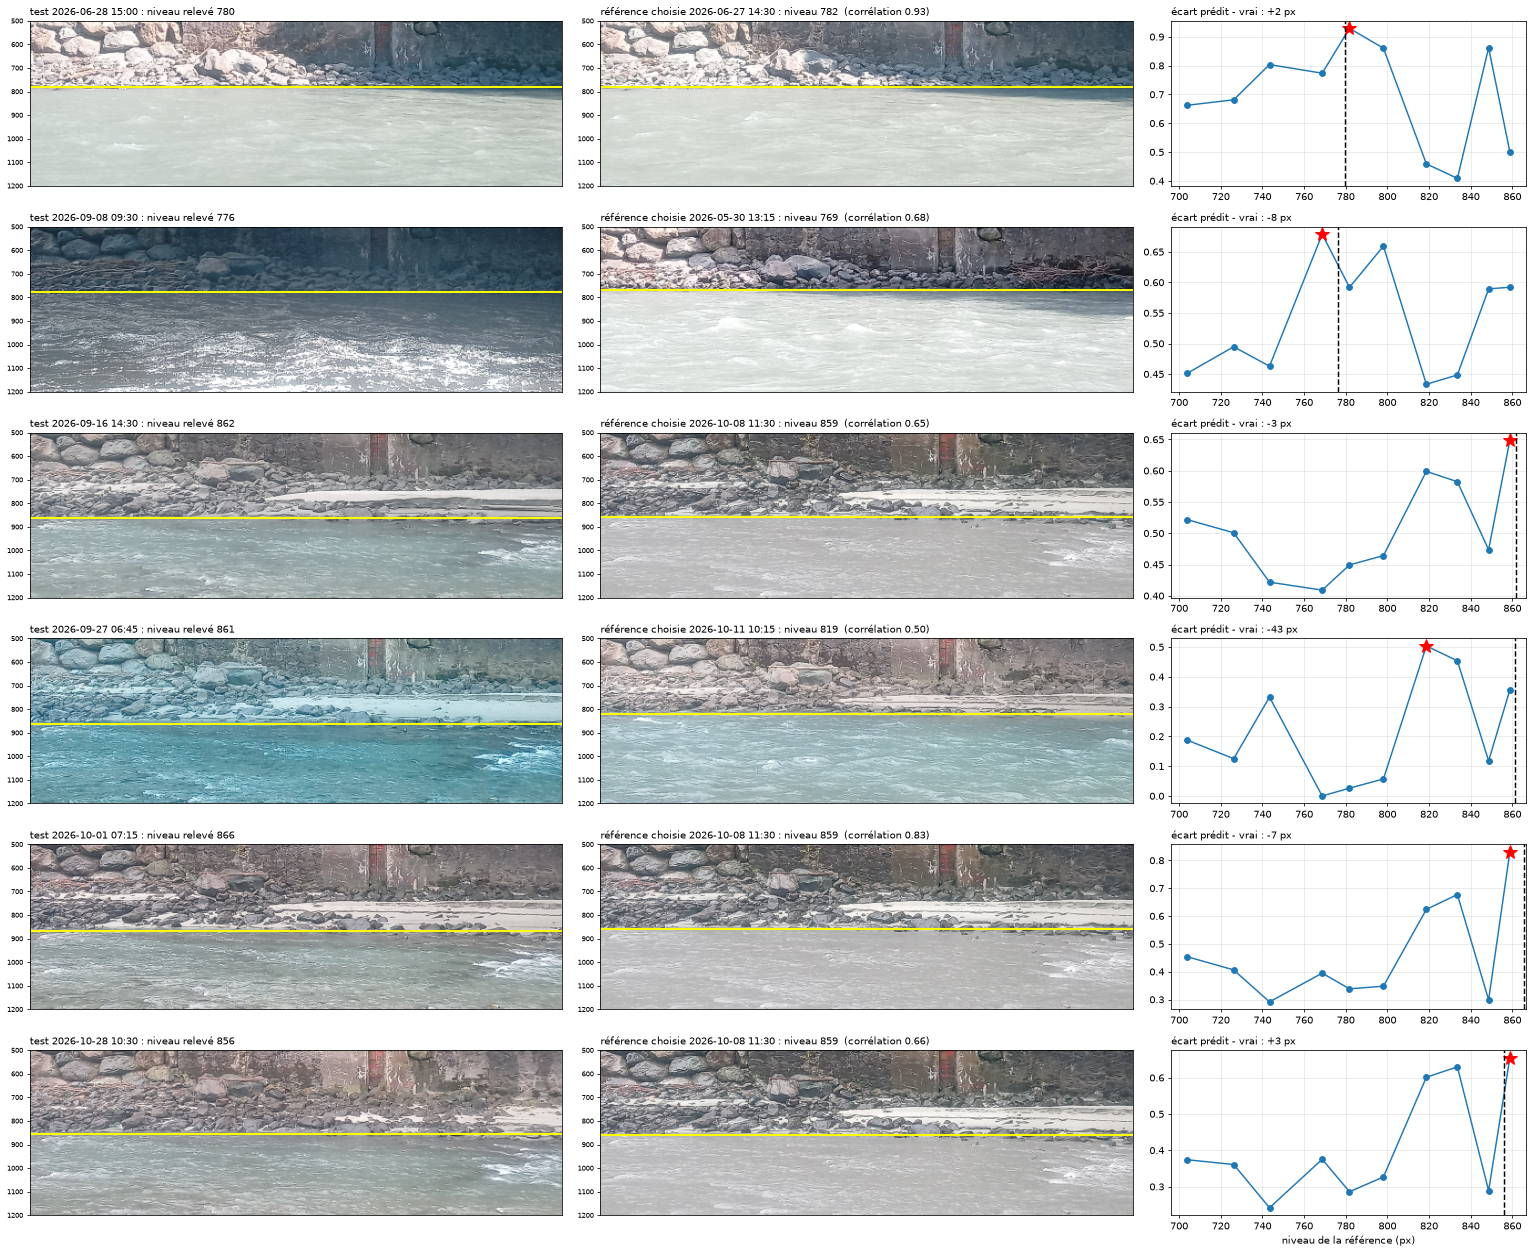

In [8]:
M = MESURES["corrélation"]
fig, ax = plt.subplots(len(TESTS), 3, figsize=(22, 3.0 * len(TESTS)), gridspec_kw={"width_ratios": [1.5, 1.5, 1]})
for i, (d, k, lv) in enumerate(TESTS):
    j = int(np.argmax(M[i]))
    show_band(ax[i, 0], k, lv, f"test {d} : niveau relevé {lv:.0f}")
    show_band(ax[i, 1], REFS[j][1], REFS[j][2],
              f"référence choisie {REFS[j][0]} : niveau {REFS[j][2]:.0f}  (corrélation {M[i, j]:.2f})")
    ax[i, 2].plot(lv_ref, M[i], "o-")
    ax[i, 2].plot(lv_ref[j], M[i, j], "r*", ms=15)
    ax[i, 2].axvline(lv, color="k", ls="--")
    ax[i, 2].set_title(f"écart prédit - vrai : {lv_ref[j] - lv:+.0f} px", loc="left", fontsize=10)
    ax[i, 2].grid(alpha=.3)
ax[-1, 2].set_xlabel("niveau de la référence (px)")
plt.tight_layout(); plt.show()

## 6. Ce qu'on en retient
- **Produit scalaire brut** : ne marche pas. Les pixels étant tous positifs, il est dominé par la **luminosité** : il désigne presque toujours la référence la plus claire, quel que soit le niveau.
- **Cosinus** : un peu mieux (le facteur de luminosité global disparaît), mais reste sensible au contraste et à la couleur.
- **Corrélation** : de loin la meilleure. En retirant à chaque image sa moyenne et son écart-type, on ne compare plus que la **forme** de l'image (où sont la berge et l'eau). 5 tests sur 6 à moins de 8 px.
- **Échec** : l'image d'aube bleutée (27/09, 6h45) est associée à une référence d'éclairage proche plutôt que de niveau proche ; ses corrélations sont toutes faibles (≤ 0,5) : une corrélation maximale faible peut servir d'alerte « prédiction peu fiable ».

**Limites** : la prédiction ne peut valoir que l'un des 10 niveaux de référence (pas de ~15-20 px), et les tests d'automne sont en haut de la gamme des références. Pistes : plus de références (notamment au-delà de 860 px), moyenne des niveaux des 2-3 meilleures références pondérée par la corrélation, ou comparaison sur la bande filtrée (passe-bande) pour être encore moins sensible à la lumière.